In [175]:
import pandas as pd
import numpy as np
import plotly as pt

import matplotlib.pyplot as plt

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import make_scorer, roc_auc_score, average_precision_score, precision_score
from sklearn.preprocessing import OrdinalEncoder

#For OS
import os

In [3]:
Test_Data = pd.read_csv('data/raw/application_test.csv')
Train_Data = pd.read_csv('data/raw/application_train.csv')

In [4]:
print(Test_Data.head())


   SK_ID_CURR NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR FLAG_OWN_REALTY  \
0      100001         Cash loans           F            N               Y   
1      100005         Cash loans           M            N               Y   
2      100013         Cash loans           M            Y               Y   
3      100028         Cash loans           F            N               Y   
4      100038         Cash loans           M            Y               N   

   CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE  \
0             0          135000.0    568800.0      20560.5         450000.0   
1             0           99000.0    222768.0      17370.0         180000.0   
2             0          202500.0    663264.0      69777.0         630000.0   
3             2          315000.0   1575000.0      49018.5        1575000.0   
4             1          180000.0    625500.0      32067.0         625500.0   

   ... FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOCUMENT_20 FLAG

In [5]:
print(Train_Data.head())

   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   
3      100006       0         Cash loans           F            N   
4      100007       0         Cash loans           M            N   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   
3               Y             0          135000.0    312682.5      29686.5   
4               Y             0          121500.0    513000.0      21865.5   

   ...  FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOCUMENT_20 FLAG_DOCUMENT_21  \
0  ...                 0             

In [6]:
print("Train_Data:", Train_Data.shape)
print("Test_Data:", Test_Data.shape)

Train_Data: (307511, 122)
Test_Data: (48744, 121)


In [7]:
print(set(Train_Data.columns) - set(Test_Data.columns))
print(set(Test_Data.columns) - set(Train_Data.columns))

{'TARGET'}
set()


In [8]:
#Train data info
Train_Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 286.2 MB


In [9]:
Train_Data.sample(5)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
192127,322787,0,Cash loans,F,N,Y,0,180000.0,454500.0,25506.0,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,4.0
138874,261029,0,Cash loans,F,N,Y,0,202500.0,1056447.0,31018.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
217488,352000,0,Cash loans,M,Y,N,0,153000.0,286704.0,20992.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,2.0
131439,252442,0,Cash loans,F,Y,Y,0,283500.0,288873.0,18589.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,8.0
23633,127504,0,Cash loans,F,N,Y,0,180000.0,1125000.0,60070.5,...,0,0,0,0,0.0,0.0,1.0,0.0,0.0,0.0


In [10]:
Train_Data.tail()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
307510,456255,0,Cash loans,F,N,N,0,157500.0,675000.0,49117.5,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


In [11]:
#Column understand
print(Train_Data.columns.tolist())

['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELE

In [12]:
#Column in list
for i, col in enumerate(Train_Data.columns, start=1):
    print(i, col)

1 SK_ID_CURR
2 TARGET
3 NAME_CONTRACT_TYPE
4 CODE_GENDER
5 FLAG_OWN_CAR
6 FLAG_OWN_REALTY
7 CNT_CHILDREN
8 AMT_INCOME_TOTAL
9 AMT_CREDIT
10 AMT_ANNUITY
11 AMT_GOODS_PRICE
12 NAME_TYPE_SUITE
13 NAME_INCOME_TYPE
14 NAME_EDUCATION_TYPE
15 NAME_FAMILY_STATUS
16 NAME_HOUSING_TYPE
17 REGION_POPULATION_RELATIVE
18 DAYS_BIRTH
19 DAYS_EMPLOYED
20 DAYS_REGISTRATION
21 DAYS_ID_PUBLISH
22 OWN_CAR_AGE
23 FLAG_MOBIL
24 FLAG_EMP_PHONE
25 FLAG_WORK_PHONE
26 FLAG_CONT_MOBILE
27 FLAG_PHONE
28 FLAG_EMAIL
29 OCCUPATION_TYPE
30 CNT_FAM_MEMBERS
31 REGION_RATING_CLIENT
32 REGION_RATING_CLIENT_W_CITY
33 WEEKDAY_APPR_PROCESS_START
34 HOUR_APPR_PROCESS_START
35 REG_REGION_NOT_LIVE_REGION
36 REG_REGION_NOT_WORK_REGION
37 LIVE_REGION_NOT_WORK_REGION
38 REG_CITY_NOT_LIVE_CITY
39 REG_CITY_NOT_WORK_CITY
40 LIVE_CITY_NOT_WORK_CITY
41 ORGANIZATION_TYPE
42 EXT_SOURCE_1
43 EXT_SOURCE_2
44 EXT_SOURCE_3
45 APARTMENTS_AVG
46 BASEMENTAREA_AVG
47 YEARS_BEGINEXPLUATATION_AVG
48 YEARS_BUILD_AVG
49 COMMONAREA_AVG
50 ELEVATORS_A

In [13]:
# numerical and categorical
numeric_cols = Train_Data.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = Train_Data.select_dtypes(
    include=["object"]
).columns

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 106
Categorical columns: 16


C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_23008\351165217.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = Train_Data.select_dtypes(


In [14]:
print("Duplicate rows:", Train_Data.duplicated().sum())
print("Duplicate SK_ID_CURR:", Train_Data["SK_ID_CURR"].duplicated().sum())

Duplicate rows: 0
Duplicate SK_ID_CURR: 0


In [15]:
#missing values
missing = Train_Data.isna().sum().sort_values(ascending=False)

print(missing.head(20))

COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
FLOORSMIN_MEDI              208642
YEARS_BUILD_AVG             204488
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
OWN_CAR_AGE                 202929
LANDAREA_MEDI               182590
LANDAREA_AVG                182590
LANDAREA_MODE               182590
dtype: int64


In [16]:
#in percentage
missing_pct = (
    Train_Data.isna().mean() * 100
).sort_values(ascending=False)

print(missing_pct.head(20))

COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
FLOORSMIN_MEDI              67.848630
YEARS_BUILD_AVG             66.497784
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_MEDI               59.376738
LANDAREA_AVG                59.376738
LANDAREA_MODE               59.376738
dtype: float64


In [17]:
#Target distribution
print(
    Train_Data["TARGET"]
    .value_counts(normalize=True)
    .mul(100)
)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


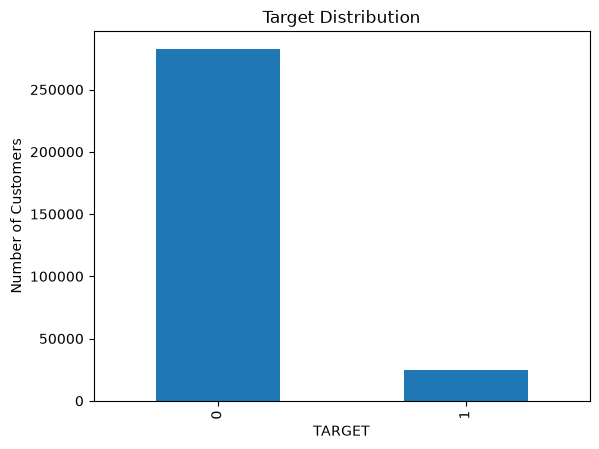

In [18]:

Train_Data["TARGET"].value_counts().plot(kind="bar")

plt.title("Target Distribution")
plt.xlabel("TARGET")
plt.ylabel("Number of Customers")
plt.show()

In [19]:
Train_Data.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


In [20]:
#Relationship with Target
Train_Data.groupby("TARGET")["AMT_INCOME_TOTAL"].median()

TARGET
0    148500.0
1    135000.0
Name: AMT_INCOME_TOTAL, dtype: float64

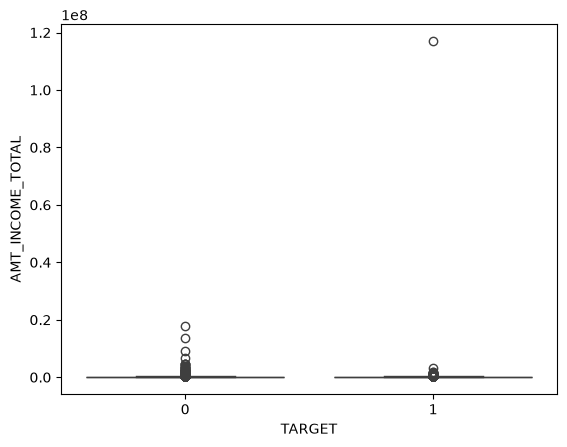

In [21]:
#Distribution
sns.boxplot(
    data=Train_Data,
    x="TARGET",
    y="AMT_INCOME_TOTAL"
)

plt.show()

In [22]:
Train_Data.isnull().sum()

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64

In [23]:
missing = Train_Data.isnull().sum().sort_values(ascending=False)

for column, count in missing.items():
    print(f"{column}: {count}")

COMMONAREA_AVG: 214865
COMMONAREA_MODE: 214865
COMMONAREA_MEDI: 214865
NONLIVINGAPARTMENTS_MEDI: 213514
NONLIVINGAPARTMENTS_MODE: 213514
NONLIVINGAPARTMENTS_AVG: 213514
FONDKAPREMONT_MODE: 210295
LIVINGAPARTMENTS_AVG: 210199
LIVINGAPARTMENTS_MEDI: 210199
LIVINGAPARTMENTS_MODE: 210199
FLOORSMIN_MODE: 208642
FLOORSMIN_AVG: 208642
FLOORSMIN_MEDI: 208642
YEARS_BUILD_AVG: 204488
YEARS_BUILD_MODE: 204488
YEARS_BUILD_MEDI: 204488
OWN_CAR_AGE: 202929
LANDAREA_MEDI: 182590
LANDAREA_AVG: 182590
LANDAREA_MODE: 182590
BASEMENTAREA_MODE: 179943
BASEMENTAREA_MEDI: 179943
BASEMENTAREA_AVG: 179943
EXT_SOURCE_1: 173378
NONLIVINGAREA_MODE: 169682
NONLIVINGAREA_AVG: 169682
NONLIVINGAREA_MEDI: 169682
ELEVATORS_AVG: 163891
ELEVATORS_MEDI: 163891
ELEVATORS_MODE: 163891
WALLSMATERIAL_MODE: 156341
APARTMENTS_AVG: 156061
APARTMENTS_MEDI: 156061
APARTMENTS_MODE: 156061
ENTRANCES_MODE: 154828
ENTRANCES_MEDI: 154828
ENTRANCES_AVG: 154828
LIVINGAREA_AVG: 154350
LIVINGAREA_MEDI: 154350
LIVINGAREA_MODE: 154350
HOUSE

In [24]:
missing = Train_Data.isnull().sum().sort_values(ascending=False)

for column, count in missing.items():
    if count > 0:
        print(f"{column}: {count}")

COMMONAREA_AVG: 214865
COMMONAREA_MODE: 214865
COMMONAREA_MEDI: 214865
NONLIVINGAPARTMENTS_MEDI: 213514
NONLIVINGAPARTMENTS_MODE: 213514
NONLIVINGAPARTMENTS_AVG: 213514
FONDKAPREMONT_MODE: 210295
LIVINGAPARTMENTS_AVG: 210199
LIVINGAPARTMENTS_MEDI: 210199
LIVINGAPARTMENTS_MODE: 210199
FLOORSMIN_MODE: 208642
FLOORSMIN_AVG: 208642
FLOORSMIN_MEDI: 208642
YEARS_BUILD_AVG: 204488
YEARS_BUILD_MODE: 204488
YEARS_BUILD_MEDI: 204488
OWN_CAR_AGE: 202929
LANDAREA_MEDI: 182590
LANDAREA_AVG: 182590
LANDAREA_MODE: 182590
BASEMENTAREA_MODE: 179943
BASEMENTAREA_MEDI: 179943
BASEMENTAREA_AVG: 179943
EXT_SOURCE_1: 173378
NONLIVINGAREA_MODE: 169682
NONLIVINGAREA_AVG: 169682
NONLIVINGAREA_MEDI: 169682
ELEVATORS_AVG: 163891
ELEVATORS_MEDI: 163891
ELEVATORS_MODE: 163891
WALLSMATERIAL_MODE: 156341
APARTMENTS_AVG: 156061
APARTMENTS_MEDI: 156061
APARTMENTS_MODE: 156061
ENTRANCES_MODE: 154828
ENTRANCES_MEDI: 154828
ENTRANCES_AVG: 154828
LIVINGAREA_AVG: 154350
LIVINGAREA_MEDI: 154350
LIVINGAREA_MODE: 154350
HOUSE

In [25]:
missing = pd.DataFrame({
    "Missing_Count": Train_Data.isnull().sum(),
    "Missing_Percentage": Train_Data.isnull().mean() * 100
})

missing = missing[missing["Missing_Count"] > 0] \
                 .sort_values("Missing_Percentage", ascending=False)

print(missing)

                          Missing_Count  Missing_Percentage
COMMONAREA_MEDI                  214865           69.872297
COMMONAREA_MODE                  214865           69.872297
COMMONAREA_AVG                   214865           69.872297
NONLIVINGAPARTMENTS_MODE         213514           69.432963
NONLIVINGAPARTMENTS_MEDI         213514           69.432963
...                                 ...                 ...
EXT_SOURCE_2                        660            0.214626
AMT_GOODS_PRICE                     278            0.090403
AMT_ANNUITY                          12            0.003902
CNT_FAM_MEMBERS                       2            0.000650
DAYS_LAST_PHONE_CHANGE                1            0.000325

[67 rows x 2 columns]


In [26]:
print("Duplicate rows:", Train_Data.duplicated().sum())
print("Duplicate SK_ID_CURR:", Train_Data["SK_ID_CURR"].duplicated().sum())

Duplicate rows: 0
Duplicate SK_ID_CURR: 0


In [27]:
print("Test duplicate rows:", Test_Data.duplicated().sum())
print("Test duplicate SK_ID_CURR:", Test_Data["SK_ID_CURR"].duplicated().sum())

Test duplicate rows: 0
Test duplicate SK_ID_CURR: 0


In [28]:
print(Train_Data.dtypes.value_counts())

float64    65
int64      41
str        16
Name: count, dtype: int64


In [29]:
numeric_cols = Train_Data.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = Train_Data.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 106
Categorical columns: 16


C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_23008\2300637909.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = Train_Data.select_dtypes(


In [30]:
Train_Data["AMT_INCOME_TOTAL"].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

In [31]:
Train_Data["NAME_CONTRACT_TYPE"].value_counts()

NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

In [32]:
Train_Data["OCCUPATION_TYPE"].value_counts(dropna=False)

OCCUPATION_TYPE
NaN                      96391
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64

In [33]:
pd.crosstab(
    Train_Data["NAME_CONTRACT_TYPE"],
    Train_Data["TARGET"],
    normalize="index"
) * 100

TARGET,0,1
NAME_CONTRACT_TYPE,,
Cash loans,91.654087,8.345913
Revolving loans,94.521671,5.478329


#checking for summary
#numeric variable eda

In [34]:
Train_Data["AMT_INCOME_TOTAL"].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

In [35]:
Train_Data["AMT_CREDIT"].describe()

count    3.075110e+05
mean     5.990260e+05
std      4.024908e+05
min      4.500000e+04
25%      2.700000e+05
50%      5.135310e+05
75%      8.086500e+05
max      4.050000e+06
Name: AMT_CREDIT, dtype: float64

In [36]:
Train_Data["AMT_ANNUITY"].describe()

count    307499.000000
mean      27108.573909
std       14493.737315
min        1615.500000
25%       16524.000000
50%       24903.000000
75%       34596.000000
max      258025.500000
Name: AMT_ANNUITY, dtype: float64

In [37]:
Train_Data["AMT_GOODS_PRICE"].describe()

count    3.072330e+05
mean     5.383962e+05
std      3.694465e+05
min      4.050000e+04
25%      2.385000e+05
50%      4.500000e+05
75%      6.795000e+05
max      4.050000e+06
Name: AMT_GOODS_PRICE, dtype: float64

In [38]:
Train_Data["DAYS_BIRTH"].describe()

count    307511.000000
mean     -16036.995067
std        4363.988632
min      -25229.000000
25%      -19682.000000
50%      -15750.000000
75%      -12413.000000
max       -7489.000000
Name: DAYS_BIRTH, dtype: float64

In [157]:
(Train_Data['DAYS_BIRTH']/-365).describe()

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: DAYS_BIRTH, dtype: float64

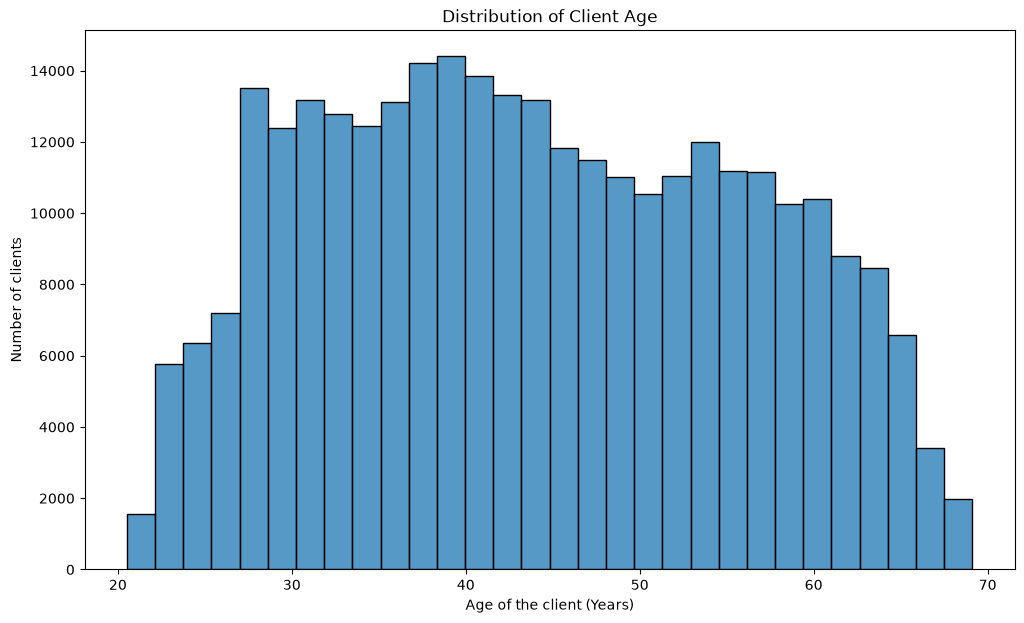

In [ ]:
## Distribution of client age 
fig, ax = plt.subplots(figsize=(12, 7))

sns.histplot(
    Train_Data["DAYS_BIRTH"] / -365,
    bins=30,
    kde=False,
    ax=ax
)

ax.set_xlabel("Age of the client (Years)")
ax.set_ylabel("Number of clients")
ax.set_title("Distribution of Client Age")

plt.show()

Interpretation: People in the age range 30-40 years are the most applicants. Which seems pretty normal.

In [39]:
Train_Data["DAYS_EMPLOYED"].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [161]:
(Train_Data['DAYS_EMPLOYED']/365).describe()

count    307511.000000
mean        174.835742
std         387.056895
min         -49.073973
25%          -7.561644
50%          -3.323288
75%          -0.791781
max        1000.665753
Name: DAYS_EMPLOYED, dtype: float64

Text(0.5, 0, 'Time before the loan application the persons started current employment(in years)')

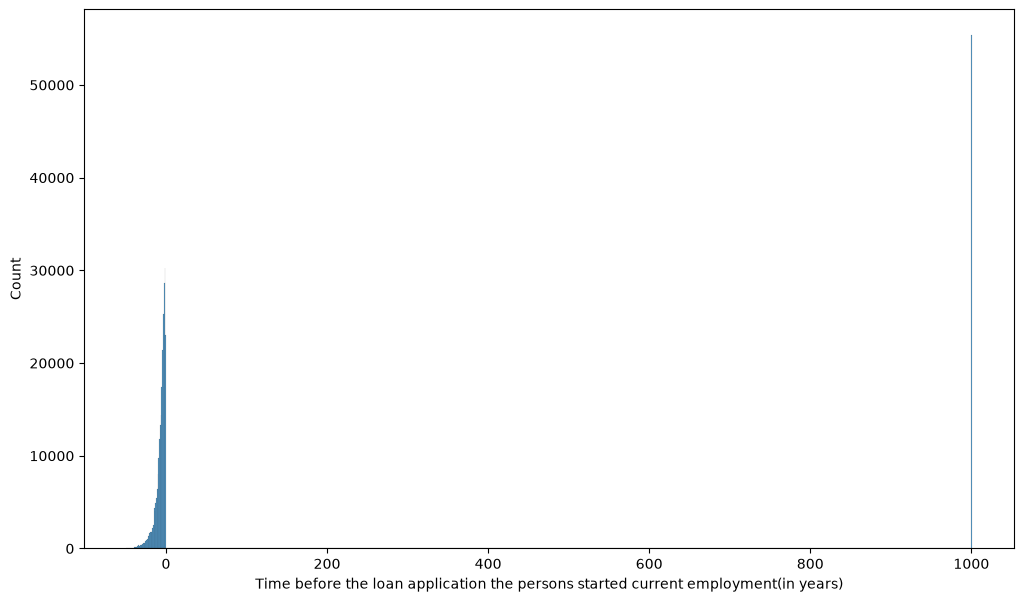

In [163]:
fig, ax = plt.subplots(figsize=(12,7))
sns.histplot(Train_Data['DAYS_EMPLOYED']/365,kde=False)
plt.xlabel("Time before the loan application the persons started current employment(in years)")

In [40]:
Train_Data["CNT_CHILDREN"].describe()

count    307511.000000
mean          0.417052
std           0.722121
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          19.000000
Name: CNT_CHILDREN, dtype: float64

In [41]:
Train_Data["CNT_FAM_MEMBERS"].describe()

count    307509.000000
mean          2.152665
std           0.910682
min           1.000000
25%           2.000000
50%           2.000000
75%           3.000000
max          20.000000
Name: CNT_FAM_MEMBERS, dtype: float64

#Categorical variables eda

In [42]:
categorical_cols = Train_Data.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    print(col)


NAME_CONTRACT_TYPE
CODE_GENDER
FLAG_OWN_CAR
FLAG_OWN_REALTY
NAME_TYPE_SUITE
NAME_INCOME_TYPE
NAME_EDUCATION_TYPE
NAME_FAMILY_STATUS
NAME_HOUSING_TYPE
OCCUPATION_TYPE
WEEKDAY_APPR_PROCESS_START
ORGANIZATION_TYPE
FONDKAPREMONT_MODE
HOUSETYPE_MODE
WALLSMATERIAL_MODE
EMERGENCYSTATE_MODE


C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_23008\1506488778.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = Train_Data.select_dtypes(


In [43]:

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(Train_Data[col].value_counts(dropna=False))


--- NAME_CONTRACT_TYPE ---
NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

--- CODE_GENDER ---
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

--- FLAG_OWN_CAR ---
FLAG_OWN_CAR
N    202924
Y    104587
Name: count, dtype: int64

--- FLAG_OWN_REALTY ---
FLAG_OWN_REALTY
Y    213312
N     94199
Name: count, dtype: int64

--- NAME_TYPE_SUITE ---
NAME_TYPE_SUITE
Unaccompanied      248526
Family              40149
Spouse, partner     11370
Children             3267
Other_B              1770
NaN                  1292
Other_A               866
Group of people       271
Name: count, dtype: int64

--- NAME_INCOME_TYPE ---
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

--- N

In [44]:
Train_Data["NAME_CONTRACT_TYPE"].value_counts()

NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

In [45]:
corr = Train_Data[numeric_cols].corr()

In [46]:
target_corr = (
    corr["TARGET"]
    .drop("TARGET")
    .sort_values()
)

print(target_corr)

EXT_SOURCE_3                  -0.178919
EXT_SOURCE_2                  -0.160472
EXT_SOURCE_1                  -0.155317
DAYS_EMPLOYED                 -0.044932
FLOORSMAX_AVG                 -0.044003
                                 ...   
DAYS_ID_PUBLISH                0.051457
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
Name: TARGET, Length: 105, dtype: float64


In [47]:
for i, col in enumerate(Train_Data.columns, start=1):
    print(i, col)

1 SK_ID_CURR
2 TARGET
3 NAME_CONTRACT_TYPE
4 CODE_GENDER
5 FLAG_OWN_CAR
6 FLAG_OWN_REALTY
7 CNT_CHILDREN
8 AMT_INCOME_TOTAL
9 AMT_CREDIT
10 AMT_ANNUITY
11 AMT_GOODS_PRICE
12 NAME_TYPE_SUITE
13 NAME_INCOME_TYPE
14 NAME_EDUCATION_TYPE
15 NAME_FAMILY_STATUS
16 NAME_HOUSING_TYPE
17 REGION_POPULATION_RELATIVE
18 DAYS_BIRTH
19 DAYS_EMPLOYED
20 DAYS_REGISTRATION
21 DAYS_ID_PUBLISH
22 OWN_CAR_AGE
23 FLAG_MOBIL
24 FLAG_EMP_PHONE
25 FLAG_WORK_PHONE
26 FLAG_CONT_MOBILE
27 FLAG_PHONE
28 FLAG_EMAIL
29 OCCUPATION_TYPE
30 CNT_FAM_MEMBERS
31 REGION_RATING_CLIENT
32 REGION_RATING_CLIENT_W_CITY
33 WEEKDAY_APPR_PROCESS_START
34 HOUR_APPR_PROCESS_START
35 REG_REGION_NOT_LIVE_REGION
36 REG_REGION_NOT_WORK_REGION
37 LIVE_REGION_NOT_WORK_REGION
38 REG_CITY_NOT_LIVE_CITY
39 REG_CITY_NOT_WORK_CITY
40 LIVE_CITY_NOT_WORK_CITY
41 ORGANIZATION_TYPE
42 EXT_SOURCE_1
43 EXT_SOURCE_2
44 EXT_SOURCE_3
45 APARTMENTS_AVG
46 BASEMENTAREA_AVG
47 YEARS_BEGINEXPLUATATION_AVG
48 YEARS_BUILD_AVG
49 COMMONAREA_AVG
50 ELEVATORS_A

##Preprocessing


In [48]:
#Keep ID separately
Train_ID = Train_Data["SK_ID_CURR"]

In [49]:
#Target
y = Train_Data["TARGET"]

In [50]:
#Features
X = Train_Data.drop(columns=["SK_ID_CURR", "TARGET"])

In [51]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 120)
y shape: (307511,)


In [52]:
#Split into training and validation
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [53]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (246008, 120)
X_val: (61503, 120)
y_train: (246008,)
y_val: (61503,)


In [ ]:
#identify numerical and categorical features
num_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))
print("Total features:", len(num_cols) + len(cat_cols))

Numerical features: 104
Categorical features: 16
Total features: 120


C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_23008\2892881655.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(


In [177]:
cat_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist() + ["CNT_CHILDREN","CNT_FAM_MEMBERS", "REGION_RATING_CLIENT","REGION_RATING_CLIENT_W_CITY"]

print(cat_cols)

ord_cols = ["AMT_REQ_CREDIT_BUREAU_HOUR","AMT_REQ_CREDIT_BUREAU_DAY","AMT_REQ_CREDIT_BUREAU_WEEK","AMT_REQ_CREDIT_BUREAU_MON","AMT_REQ_CREDIT_BUREAU_QRT","AMT_REQ_CREDIT_BUREAU_YEAR"]

binary_cols = ["FLAG_MOBIL","FLAG_EMP_PHONE","FLAG_WORK_PHONE","FLAG_CONT_MOBILE","FLAG_PHONE","FLAG_EMAIL","REG_REGION_NOT_LIVE_REGION","REG_REGION_NOT_WORK_REGION","LIVE_REGION_NOT_WORK_REGION",
"REG_CITY_NOT_LIVE_CITY",
"REG_CITY_NOT_WORK_CITY",
"LIVE_CITY_NOT_WORK_CITY","FLAG_DOCUMENT_2","FLAG_DOCUMENT_3",
"FLAG_DOCUMENT_4","FLAG_DOCUMENT_5","FLAG_DOCUMENT_6",
"FLAG_DOCUMENT_7","FLAG_DOCUMENT_8","FLAG_DOCUMENT_9","FLAG_DOCUMENT_10","FLAG_DOCUMENT_11","FLAG_DOCUMENT_12","FLAG_DOCUMENT_13",
"FLAG_DOCUMENT_14","FLAG_DOCUMENT_15","FLAG_DOCUMENT_16","FLAG_DOCUMENT_17",
"FLAG_DOCUMENT_18","FLAG_DOCUMENT_19","FLAG_DOCUMENT_20","FLAG_DOCUMENT_21"]

numeric_cols =X_train.drop(columns=cat_cols+ord_cols+binary_cols).columns.tolist()
print(numeric_cols)

print(len(cat_cols)+len(numeric_cols)+len(ord_cols)+len(binary_cols))

['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY']
['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'HOUR_APPR_PROCESS_START', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE

C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_23008\1328800354.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(


In [55]:
#proportion of defaults is similar in train and validation.
print("Training target:")
print(y_train.value_counts(normalize=True))

print("\nValidation target:")
print(y_val.value_counts(normalize=True))

Training target:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Validation target:
TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


## Preprocessing pipeline

In [180]:
#Create preprocessing pipelines
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

#Categorical features
#Fill missing values with most frequent category
#One-hot encode
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        ))
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="ignore"
    ))
])


#Combine them
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num_cols", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, cat_cols),
    ("binary", binary_pipeline, binary_cols),
    ("ordinal", ordinal_pipeline, ord_cols)
])

In [181]:
print("Shape:", Train_Data.shape)

Shape: (307511, 122)


In [182]:
print("SK_ID_CURR exists:", "SK_ID_CURR" in Train_Data.columns)
print("TARGET exists:", "TARGET" in Train_Data.columns)

SK_ID_CURR exists: True
TARGET exists: True


In [183]:
print("Duplicate IDs:", Train_Data["SK_ID_CURR"].duplicated().sum())

Duplicate IDs: 0


In [184]:
print("Duplicate rows:", Train_Data.duplicated().sum())

Duplicate rows: 0


In [61]:
print(Train_Data["TARGET"].value_counts())

TARGET
0    282686
1     24825
Name: count, dtype: int64


In [62]:
print(Train_Data["TARGET"].unique())

[1 0]


In [63]:
print(Train_Data.dtypes.value_counts())

float64    65
int64      41
str        16
Name: count, dtype: int64


In [64]:
print(Train_Data.info())

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 286.2 MB
None


In [65]:
missing = Train_Data.isna().sum()

print("Total missing values:", missing.sum())
print("Columns with missing values:", (missing > 0).sum())

Total missing values: 9152465
Columns with missing values: 67


In [66]:
print("Train_Data:", Train_Data.shape)
print("X:", X.shape)
print("y:", y.shape)
print("Train_ID:", Train_ID.shape)

Train_Data: (307511, 122)
X: (307511, 120)
y: (307511,)
Train_ID: (307511,)


In [67]:
print("Original columns:", Train_Data.shape[1])
print("ID + TARGET + features:", 1 + 1 + X.shape[1])

Original columns: 122
ID + TARGET + features: 122


In [68]:
print(len(num_cols))
print(len(cat_cols))
print(len(num_cols) + len(cat_cols))

104
16
120


### Modeling

In [149]:
from sklearn.dummy import DummyClassifier

dummy_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

dummy_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_MON','AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns

In [150]:
y_pred_dummy = dummy_model.predict(X_val)

In [151]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_val, y_pred_dummy))
print("Precision:", precision_score(y_val, y_pred_dummy, zero_division=0))
print("Recall:", recall_score(y_val, y_pred_dummy, zero_division=0))
print("F1:", f1_score(y_val, y_pred_dummy, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_dummy))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_dummy, zero_division=0))

Accuracy: 0.9192722306228964
Precision: 0.0
Recall: 0.0
F1: 0.0

Confusion Matrix:
[[56538     0]
 [ 4965     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.00      0.00      0.00      4965

    accuracy                           0.92     61503
   macro avg       0.46      0.50      0.48     61503
weighted avg       0.85      0.92      0.88     61503



In [152]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
         random_state=42
    ))
])

In [153]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_MON','AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns

In [154]:
y_val_pred = baseline_model.predict(X_val)

In [155]:
y_val_prob = baseline_model.predict_proba(X_val)[:, 1]

In [156]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("ROC-AUC:",
      roc_auc_score(y_val, y_val_prob))

print("PR-AUC:",
      average_precision_score(y_val, y_val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

ROC-AUC: 0.7503659010077867
PR-AUC: 0.23239085488052194

Confusion Matrix:
[[38912 17626]
 [ 1593  3372]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.69      0.80     56538
           1       0.16      0.68      0.26      4965

    accuracy                           0.69     61503
   macro avg       0.56      0.68      0.53     61503
weighted avg       0.90      0.69      0.76     61503



In [132]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    baseline_model,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, w

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

In [74]:
from sklearn.tree import DecisionTreeClassifier


dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

In [75]:
dt_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_MON','AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns

In [76]:
y_pred = dt_pipeline.predict(X_val)
y_prob = dt_pipeline.predict_proba(X_val)[:, 1]

In [77]:
from sklearn.metrics import (
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

print("ROC-AUC:", roc_auc_score(y_val, y_prob))
print("Recall:", recall_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("F1:", f1_score(y_val, y_pred))
print("F2:", fbeta_score(y_val, y_pred, beta=2))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred))

ROC-AUC: 0.5408958111641942
Recall: 0.16294058408862033
Precision: 0.14989809153233277
F1: 0.15614746187994596
F2: 0.16015362077839806
Confusion Matrix:
 [[51950  4588]
 [ 4156   809]]


In [78]:
param_grid_small = {
    "model__max_depth": [5, 10, 15],
    "model__min_samples_leaf": [5, 10],
    "model__class_weight": [None, "balanced"]
}

In [79]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [80]:
from sklearn.model_selection import RandomizedSearchCV

dt_random = RandomizedSearchCV(
    estimator=dt_pipeline,
    param_distributions=param_grid_small,
    n_iter=3,
    scoring="roc_auc",
    cv=2,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

dt_random.fit(X_train, y_train)

Fitting 2 folds for each of 3 candidates, totalling 6 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [5, 10]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected `

In [81]:
print("Best parameters:")
print(dt_random.best_params_)

print("Best CV ROC-AUC:")
print(dt_random.best_score_)

Best parameters:
{'model__min_samples_leaf': 5, 'model__max_depth': 5, 'model__class_weight': None}
Best CV ROC-AUC:
0.7057688872160842


In [82]:
best_dt = dt_random.best_estimator_

y_pred_dt_tuned = best_dt.predict(X_val)
y_prob_dt_tuned = best_dt.predict_proba(X_val)[:, 1]

In [83]:
from sklearn.metrics import (
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

print("ROC-AUC:", roc_auc_score(y_val, y_prob_dt_tuned))
print("Recall:", recall_score(y_val, y_pred_dt_tuned))
print("Precision:", precision_score(y_val, y_pred_dt_tuned))
print("F1:", f1_score(y_val, y_pred_dt_tuned))
print("F2:", fbeta_score(y_val, y_pred_dt_tuned, beta=2))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_dt_tuned))

ROC-AUC: 0.7094816996416637
Recall: 0.0
Precision: 0.0
F1: 0.0
F2: 0.0
Confusion Matrix:
[[56538     0]
 [ 4965     0]]


c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [84]:
print(dt_random.best_params_)

{'model__min_samples_leaf': 5, 'model__max_depth': 5, 'model__class_weight': None}


In [85]:
dt_pipeline_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

In [86]:
param_grid_small = {
    "model__max_depth": [3, 5, 7, 10],
    "model__min_samples_leaf": [5, 10, 20]
}

In [87]:
dt_random_balanced = RandomizedSearchCV(
    estimator=dt_pipeline_balanced,
    param_distributions=param_grid_small,
    n_iter=6,
    scoring="roc_auc",
    cv=2,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

dt_random_balanced.fit(X_train, y_train)

Fitting 2 folds for each of 6 candidates, totalling 12 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [5, 10, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",6
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_`

In [88]:
print(dt_random_balanced.best_params_)
print(dt_random_balanced.best_score_)

{'model__min_samples_leaf': 20, 'model__max_depth': 7}
0.7085123690532599


In [89]:
best_dt_balanced = dt_random_balanced.best_estimator_

y_pred_balanced = best_dt_balanced.predict(X_val)
y_prob_balanced = best_dt_balanced.predict_proba(X_val)[:, 1]

In [90]:
print("ROC-AUC:", roc_auc_score(y_val, y_prob_balanced))
print("Recall:", recall_score(y_val, y_pred_balanced))
print("Precision:", precision_score(y_val, y_pred_balanced))
print("F1:", f1_score(y_val, y_pred_balanced))
print("F2:", fbeta_score(y_val, y_pred_balanced, beta=2))
print(confusion_matrix(y_val, y_pred_balanced))

ROC-AUC: 0.7175700240214878
Recall: 0.6666666666666666
Precision: 0.1474190531332116
F1: 0.24144722445109051
F2: 0.391132748800605
[[37395 19143]
 [ 1655  3310]]


In [91]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [92]:
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, 15],
    "model__min_samples_leaf": [5, 10, 20],
    "model__max_features": ["sqrt", "log2"]
}

In [93]:

cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

rf_random = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    n_iter=5,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [94]:
rf_random.fit(X_train, y_train)

Fitting 2 folds for each of 5 candidates, totalling 10 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [5, 10, ...], 'model__max_features': ['sqrt', 'log2'], 'model__min_samples_leaf': [5, 10, ...], 'model__n_estimators': [100, 200]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estima

In [95]:
print("Best parameters:")
print(rf_random.best_params_)

print("Best CV ROC-AUC:")
print(rf_random.best_score_)

Best parameters:
{'model__n_estimators': 100, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 15}
Best CV ROC-AUC:
0.7292446265126202


In [96]:
best_rf = rf_random.best_estimator_

y_pred_rf = best_rf.predict(X_val)
y_prob_rf = best_rf.predict_proba(X_val)[:, 1]

In [97]:
from sklearn.metrics import (
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

print("ROC-AUC:", roc_auc_score(y_val, y_prob_rf))
print("Recall:", recall_score(y_val, y_pred_rf))
print("Precision:", precision_score(y_val, y_pred_rf))
print("F1:", f1_score(y_val, y_pred_rf))
print("F2:", fbeta_score(y_val, y_pred_rf, beta=2))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_rf))

ROC-AUC: 0.7366347765926095
Recall: 0.5691842900302114
Precision: 0.1758337481333997
F1: 0.26866948709416744
F2: 0.39324279194033174
Confusion Matrix:
[[43292 13246]
 [ 2139  2826]]


In [98]:
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:
    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Recall: {recall_score(y_val, y_pred_threshold):.3f} | "
        f"Precision: {precision_score(y_val, y_pred_threshold):.3f} | "
        f"F1: {f1_score(y_val, y_pred_threshold):.3f} | "
        f"F2: {fbeta_score(y_val, y_pred_threshold, beta=2):.3f}"
    )

Threshold: 0.20 | Recall: 0.995 | Precision: 0.084 | F1: 0.155 | F2: 0.314
Threshold: 0.25 | Recall: 0.973 | Precision: 0.090 | F1: 0.165 | F2: 0.329
Threshold: 0.30 | Recall: 0.930 | Precision: 0.100 | F1: 0.181 | F2: 0.351
Threshold: 0.35 | Recall: 0.870 | Precision: 0.115 | F1: 0.202 | F2: 0.375
Threshold: 0.40 | Recall: 0.784 | Precision: 0.131 | F1: 0.225 | F2: 0.393
Threshold: 0.45 | Recall: 0.687 | Precision: 0.153 | F1: 0.251 | F2: 0.405
Threshold: 0.50 | Recall: 0.569 | Precision: 0.176 | F1: 0.269 | F2: 0.393


In [99]:
best_rf = rf_random.best_estimator_

rf_model = best_rf.named_steps["model"]
preprocessor_fitted = best_rf.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

importance.head(20)

,Feature,Importance
29,numeric__EXT_SOURCE_3,0.134563
28,numeric__EXT_SOURCE_2,0.125306
27,numeric__EXT_SOURCE_1,0.053303
6,numeric__DAYS_BIRTH,0.037117
7,numeric__DAYS_EMPLOYED,0.033228
77,numeric__DAYS_LAST_PHONE_CHANGE,0.027839
4,numeric__AMT_GOODS_PRICE,0.027714
2,numeric__AMT_CREDIT,0.024127
9,numeric__DAYS_ID_PUBLISH,0.022006
3,numeric__AMT_ANNUITY,0.020276


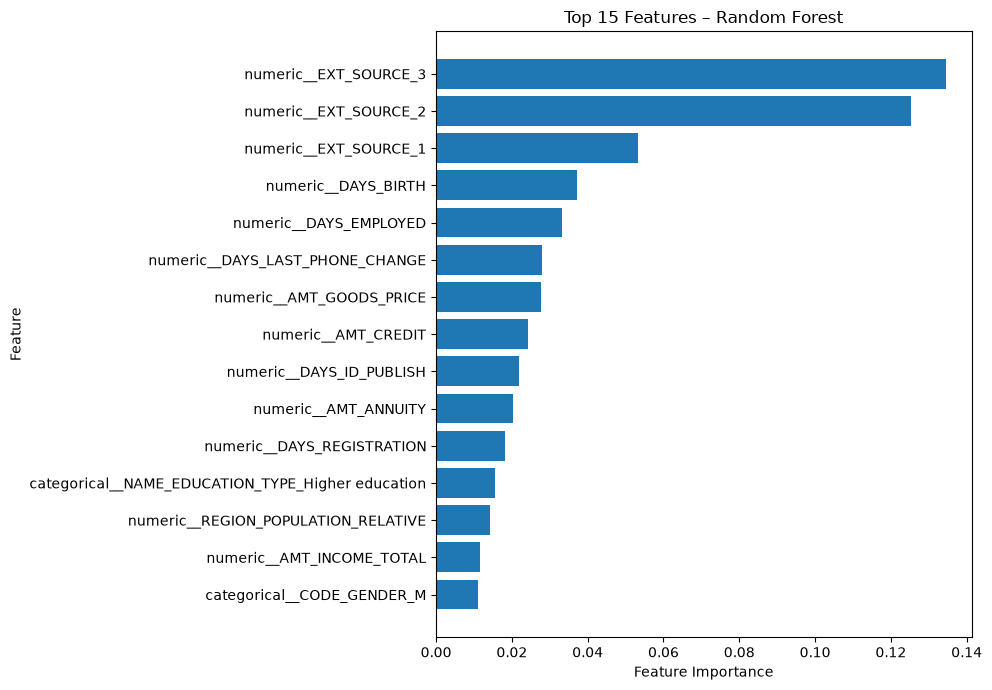

In [100]:
import matplotlib.pyplot as plt

top_15 = importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_15["Feature"], top_15["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features – Random Forest")
plt.tight_layout()
plt.show()

In [101]:
thresholds = np.arange(0.40, 0.501, 0.01)

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Recall": recall_score(y_val, y_pred_threshold),
        "Precision": precision_score(y_val, y_pred_threshold),
        "F1": f1_score(y_val, y_pred_threshold),
        "F2": fbeta_score(y_val, y_pred_threshold, beta=2)
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results.sort_values(
    "F2",
    ascending=False
).head(10)

,Threshold,Recall,Precision,F1,F2
5,0.45,0.687412,0.153207,0.250569,0.404988
6,0.46,0.665861,0.157752,0.255073,0.404978
7,0.47,0.644109,0.162294,0.259262,0.404145
4,0.44,0.706747,0.148253,0.245093,0.403065
8,0.48,0.620342,0.166838,0.262956,0.401868
3,0.43,0.726284,0.143437,0.239562,0.400667
2,0.42,0.748439,0.139437,0.235078,0.399484
9,0.49,0.595569,0.171331,0.266109,0.398314
1,0.41,0.766969,0.135299,0.230021,0.396625
10,0.50,0.569184,0.175834,0.268669,0.393243


In [102]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print(scale_pos_weight)

11.38710976837865


In [103]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="auc",
        random_state=42,
        n_jobs=-1
    ))
])

In [104]:
xgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_MON','AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns

In [105]:
y_pred_xgb = xgb_pipeline.predict(X_val)

y_prob_xgb = xgb_pipeline.predict_proba(X_val)[:, 1]

In [106]:
from sklearn.metrics import (
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

print("ROC-AUC:", roc_auc_score(y_val, y_prob_xgb))
print("Recall:", recall_score(y_val, y_pred_xgb))
print("Precision:", precision_score(y_val, y_pred_xgb))
print("F1:", f1_score(y_val, y_pred_xgb))
print("F2:", fbeta_score(y_val, y_pred_xgb, beta=2))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_xgb))

ROC-AUC: 0.7568394107722894
Recall: 0.683987915407855
Precision: 0.16557776694295465
F1: 0.2666143277723258
F2: 0.42060936338865496
Confusion Matrix:
[[39424 17114]
 [ 1569  3396]]


In [107]:
thresholds = np.arange(0.20, 0.61, 0.05)

for threshold in thresholds:
    y_pred_threshold = (y_prob_xgb >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Recall: {recall_score(y_val, y_pred_threshold):.3f} | "
        f"Precision: {precision_score(y_val, y_pred_threshold):.3f} | "
        f"F1: {f1_score(y_val, y_pred_threshold):.3f} | "
        f"F2: {fbeta_score(y_val, y_pred_threshold, beta=2):.3f}"
    )

Threshold: 0.20 | Recall: 0.976 | Precision: 0.091 | F1: 0.166 | F2: 0.331
Threshold: 0.25 | Recall: 0.946 | Precision: 0.099 | F1: 0.179 | F2: 0.349
Threshold: 0.30 | Recall: 0.909 | Precision: 0.109 | F1: 0.195 | F2: 0.368
Threshold: 0.35 | Recall: 0.870 | Precision: 0.121 | F1: 0.213 | F2: 0.389
Threshold: 0.40 | Recall: 0.816 | Precision: 0.134 | F1: 0.230 | F2: 0.404
Threshold: 0.45 | Recall: 0.753 | Precision: 0.149 | F1: 0.249 | F2: 0.416
Threshold: 0.50 | Recall: 0.684 | Precision: 0.166 | F1: 0.267 | F2: 0.421
Threshold: 0.55 | Recall: 0.609 | Precision: 0.186 | F1: 0.285 | F2: 0.418
Threshold: 0.60 | Recall: 0.517 | Precision: 0.209 | F1: 0.298 | F2: 0.399


In [108]:
##Test Data

In [109]:
print(Test_Data.shape)
print(Test_Data.head())
print(Test_Data.columns.tolist())

(48744, 121)
   SK_ID_CURR NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR FLAG_OWN_REALTY  \
0      100001         Cash loans           F            N               Y   
1      100005         Cash loans           M            N               Y   
2      100013         Cash loans           M            Y               Y   
3      100028         Cash loans           F            N               Y   
4      100038         Cash loans           M            Y               N   

   CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE  \
0             0          135000.0    568800.0      20560.5         450000.0   
1             0           99000.0    222768.0      17370.0         180000.0   
2             0          202500.0    663264.0      69777.0         630000.0   
3             2          315000.0   1575000.0      49018.5        1575000.0   
4             1          180000.0    625500.0      32067.0         625500.0   

   ... FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOC

In [110]:
print("TARGET" in Test_Data.columns)

False


In [111]:
xgb_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_MON','AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns

In [112]:
test_prob = xgb_pipeline.predict_proba(Test_Data)[:, 1]

In [113]:
print(test_prob[:10])
print(test_prob.min())
print(test_prob.max())

[0.35081345 0.54815817 0.14282706 0.33654416 0.6398145  0.34395322
 0.16374129 0.3976509  0.17684887 0.46225846]
0.03353338
0.94812673


In [114]:
test_pred = (test_prob >= 0.50).astype(int)

In [115]:
submission = pd.DataFrame({
    "SK_ID_CURR": Test_Data["SK_ID_CURR"],
    "TARGET": test_prob
})

In [116]:
print(submission.head())
print(submission.shape)

   SK_ID_CURR    TARGET
0      100001  0.350813
1      100005  0.548158
2      100013  0.142827
3      100028  0.336544
4      100038  0.639814
(48744, 2)


In [117]:
Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(...))
])

c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\xgboost\core.py:566: FutureWarning: Pass `objective` as keyword args.
  warnings.warn(msg, FutureWarning)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defau

In [118]:
xgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_MON','AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns

In [119]:
xgb_pipeline.predict(X_val)

array([0, 0, 1, ..., 0, 1, 1], shape=(61503,))